# LAB1 - Phần 2 - Bài 5a (Trang 45): Online Retail - Nước Đức (Germany)
**Phạm Quốc Thuận - 6451071076 - CNTT.64**

Thực hiện lại bài tập lập trình ở phần hướng dẫn chung với: **Germany, min_sup = 5%, min_conf = 50%**.

In [1]:
# Cài thư viện (chỉ cần chạy 1 lần): pip install mlxtend openpyxl
import pandas as pd
import matplotlib.pyplot as plt
import time
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 20)
pd.set_option('display.width', 200)

## Câu 1: Đọc dữ liệu vào chương trình

In [2]:
print("Họ tên: Phạm Quốc Thuận - MSSV: 6451071076 - Lớp: CNTT.64")
df = pd.read_excel('../Dataset/Online Retail.xlsx')   # file lớn, đọc mất khoảng 1 phút
print('Kích thước dữ liệu:', df.shape)
display(df.head())
df.info()

Họ tên: Phạm Quốc Thuận - MSSV: 6451071076 - Lớp: CNTT.64


Kích thước dữ liệu: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB


## Câu 2: Cắt ký tự thừa ở Description, xóa dòng không có InvoiceNo, chuyển InvoiceNo về chuỗi

In [3]:
print("Họ tên: Phạm Quốc Thuận - MSSV: 6451071076 - Lớp: CNTT.64")
df['Description'] = df['Description'].str.strip()
df = df.dropna(axis=0, subset=['InvoiceNo'])
df['InvoiceNo'] = df['InvoiceNo'].astype(str)
print('Kích thước sau khi làm sạch:', df.shape)
df.head(10)

Họ tên: Phạm Quốc Thuận - MSSV: 6451071076 - Lớp: CNTT.64


Kích thước sau khi làm sạch: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
5,536365,22752,SET 7 BABUSHKA NESTING BOXES,2,2010-12-01 08:26:00,7.65,17850.0,United Kingdom
6,536365,21730,GLASS STAR FROSTED T-LIGHT HOLDER,6,2010-12-01 08:26:00,4.25,17850.0,United Kingdom
7,536366,22633,HAND WARMER UNION JACK,6,2010-12-01 08:28:00,1.85,17850.0,United Kingdom
8,536366,22632,HAND WARMER RED POLKA DOT,6,2010-12-01 08:28:00,1.85,17850.0,United Kingdom
9,536367,84879,ASSORTED COLOUR BIRD ORNAMENT,32,2010-12-01 08:34:00,1.69,13047.0,United Kingdom


## Câu 3: Xóa các hóa đơn tín dụng (InvoiceNo chứa ký tự 'C')

In [4]:
print("Họ tên: Phạm Quốc Thuận - MSSV: 6451071076 - Lớp: CNTT.64")
display(df[df['InvoiceNo'].str.contains('C')].head())
print('Số dòng hóa đơn tín dụng:', df['InvoiceNo'].str.contains('C').sum())
df = df[~df['InvoiceNo'].str.contains('C')]
print('Kích thước sau khi xóa:', df.shape)

Họ tên: Phạm Quốc Thuận - MSSV: 6451071076 - Lớp: CNTT.64


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom


Số dòng hóa đơn tín dụng: 9288
Kích thước sau khi xóa: (532621, 8)


## Câu 4: Thống kê số dòng dữ liệu theo từng quốc gia

Họ tên: Phạm Quốc Thuận - MSSV: 6451071076 - Lớp: CNTT.64
Country
United Kingdom    487622
Germany             9042
France              8408
EIRE                7894
Spain               2485
Netherlands         2363
Belgium             2031
Switzerland         1967
Portugal            1501
Australia           1185
Name: count, dtype: int64


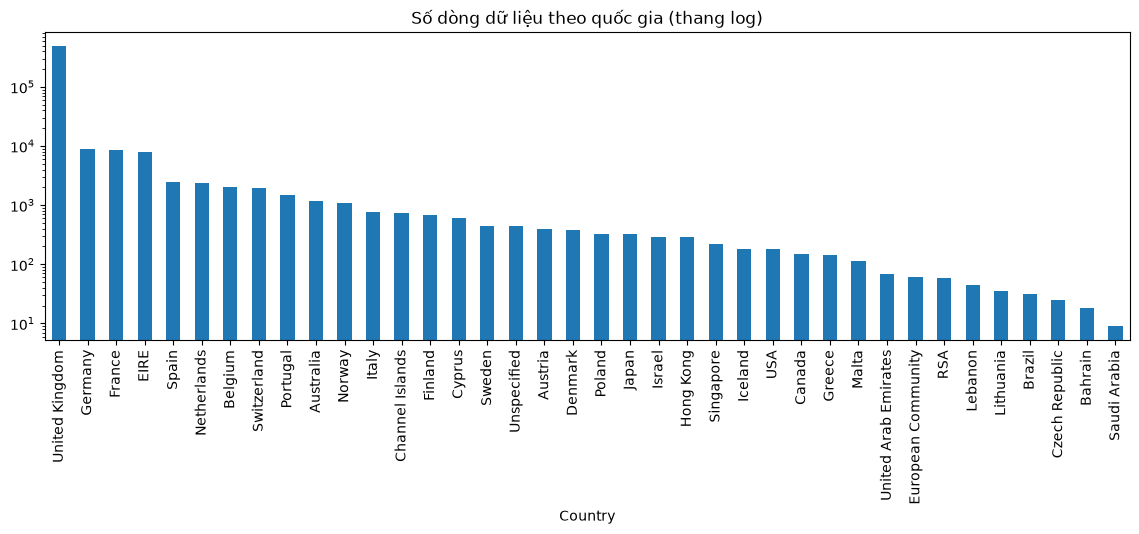

In [5]:
print("Họ tên: Phạm Quốc Thuận - MSSV: 6451071076 - Lớp: CNTT.64")
country_counts = df['Country'].value_counts()
print(country_counts.head(10))
country_counts.plot(kind='bar', figsize=(14, 4), logy=True, title='Số dòng dữ liệu theo quốc gia (thang log)')
plt.show()

## Câu 5: Lấy hóa đơn từ 'Germany', gom nhóm Quantity theo InvoiceNo và Description

In [6]:
print("Họ tên: Phạm Quốc Thuận - MSSV: 6451071076 - Lớp: CNTT.64")
COUNTRY = 'Germany'
grouped = (df[df['Country'] == COUNTRY]
           .groupby(['InvoiceNo', 'Description'])['Quantity'].sum())
print('Số dòng sau khi gom nhóm:', len(grouped))
grouped.head(10)

Họ tên: Phạm Quốc Thuận - MSSV: 6451071076 - Lớp: CNTT.64
Số dòng sau khi gom nhóm: 9015


InvoiceNo  Description                        
536527     3 HOOK HANGER MAGIC GARDEN             12
           5 HOOK HANGER MAGIC TOADSTOOL          12
           5 HOOK HANGER RED MAGIC TOADSTOOL      12
           ASSORTED COLOUR LIZARD SUCTION HOOK    24
           CHILDREN'S CIRCUS PARADE MUG           12
           HOMEMADE JAM SCENTED CANDLES           12
           HOT WATER BOTTLE BABUSHKA               4
           JUMBO BAG OWLS                         10
           JUMBO BAG WOODLAND ANIMALS             10
           MULTI COLOUR SILVER T-LIGHT HOLDER     12
Name: Quantity, dtype: int64

## Câu 6: Chuyển dữ liệu về dạng hot encoding (mỗi dòng là một hóa đơn)

In [7]:
print("Họ tên: Phạm Quốc Thuận - MSSV: 6451071076 - Lớp: CNTT.64")
basket = grouped.unstack().reset_index().fillna(0).set_index('InvoiceNo')
print('Kích thước basket (số hóa đơn x số mặt hàng):', basket.shape)
basket.iloc[:5, :8]

Họ tên: Phạm Quốc Thuận - MSSV: 6451071076 - Lớp: CNTT.64
Kích thước basket (số hóa đơn x số mặt hàng): (457, 1695)


Description,10 COLOUR SPACEBOY PEN,12 COLOURED PARTY BALLOONS,12 IVORY ROSE PEG PLACE SETTINGS,12 MESSAGE CARDS WITH ENVELOPES,12 PENCIL SMALL TUBE WOODLAND,12 PENCILS SMALL TUBE RED RETROSPOT,12 PENCILS SMALL TUBE SKULL,12 PENCILS TALL TUBE POSY
InvoiceNo,,,,,,,,
536527,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
536840,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
536861,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
536967,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
536983,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## Câu 7: Chuyển từ hot encoding sang one-hot encoding

In [8]:
print("Họ tên: Phạm Quốc Thuận - MSSV: 6451071076 - Lớp: CNTT.64")
def encode_units(x):
    return 1 if x > 0 else 0

basket_sets = basket.map(encode_units).astype(bool)
basket_sets.iloc[:5, :8]

Họ tên: Phạm Quốc Thuận - MSSV: 6451071076 - Lớp: CNTT.64


Description,10 COLOUR SPACEBOY PEN,12 COLOURED PARTY BALLOONS,12 IVORY ROSE PEG PLACE SETTINGS,12 MESSAGE CARDS WITH ENVELOPES,12 PENCIL SMALL TUBE WOODLAND,12 PENCILS SMALL TUBE RED RETROSPOT,12 PENCILS SMALL TUBE SKULL,12 PENCILS TALL TUBE POSY
InvoiceNo,,,,,,,,
536527,False,False,False,False,False,False,False,False
536840,False,False,False,False,False,False,False,False
536861,False,False,False,False,False,False,False,False
536967,False,False,False,False,False,False,False,False
536983,False,False,False,False,False,False,False,False


## Câu 8: Xóa cột 'POSTAGE'

In [9]:
print("Họ tên: Phạm Quốc Thuận - MSSV: 6451071076 - Lớp: CNTT.64")
print('Có cột POSTAGE:', 'POSTAGE' in basket_sets.columns)
basket_sets = basket_sets.drop(columns=['POSTAGE'], errors='ignore')
print('Kích thước sau khi xóa:', basket_sets.shape)

Họ tên: Phạm Quốc Thuận - MSSV: 6451071076 - Lớp: CNTT.64
Có cột POSTAGE: True
Kích thước sau khi xóa: (457, 1694)


## Câu 9: Tìm tập phổ biến bằng Apriori với min_sup = 5%

In [10]:
print("Họ tên: Phạm Quốc Thuận - MSSV: 6451071076 - Lớp: CNTT.64")
MIN_SUP = 0.05
start = time.time()
frequent_itemsets = apriori(basket_sets, min_support=MIN_SUP, use_colnames=True)
apriori_time = time.time() - start
print('Số tập phổ biến tìm được:', len(frequent_itemsets), '| thời gian: %.3f s' % apriori_time)
frequent_itemsets.sort_values('support', ascending=False).head(10)

Họ tên: Phạm Quốc Thuận - MSSV: 6451071076 - Lớp: CNTT.64
Số tập phổ biến tìm được: 59 | thời gian: 0.006 s


,support,itemsets
35,0.245077,frozenset({ROUND SNACK BOXES SET OF4 WOODLAND})
34,0.157549,frozenset({ROUND SNACK BOXES SET OF 4 FRUITS})
24,0.137856,frozenset({PLASTERS IN TIN WOODLAND ANIMALS})
31,0.137856,frozenset({REGENCY CAKESTAND 3 TIER})
56,0.131291,"frozenset({ROUND SNACK BOXES SET OF 4 FRUITS, ..."
48,0.126915,frozenset({WOODLAND CHARLOTTE BAG})
21,0.115974,frozenset({PLASTERS IN TIN CIRCUS PARADE})
22,0.107221,frozenset({PLASTERS IN TIN SPACEBOY})
0,0.102845,frozenset({6 RIBBONS RUSTIC CHARM})
44,0.102845,frozenset({SPACEBOY LUNCH BOX})


## Câu 10: Tạo luật kết hợp với min_conf = 50% và in ra các luật

In [11]:
print("Họ tên: Phạm Quốc Thuận - MSSV: 6451071076 - Lớp: CNTT.64")
MIN_CONF = 0.5
rules = association_rules(frequent_itemsets, metric='confidence', min_threshold=MIN_CONF)
rules['antecedents'] = rules['antecedents'].apply(lambda x: ', '.join(sorted(x)))
rules['consequents'] = rules['consequents'].apply(lambda x: ', '.join(sorted(x)))
print('Số luật tìm được:', len(rules))
for i, r in rules.sort_values('confidence', ascending=False).iterrows():
    print(f"{r['antecedents']}  =>  {r['consequents']}   (sup={r['support']:.3f}, conf={r['confidence']:.3f}, lift={r['lift']:.2f})")

Họ tên: Phạm Quốc Thuận - MSSV: 6451071076 - Lớp: CNTT.64
Số luật tìm được: 8
RED RETROSPOT CHARLOTTE BAG  =>  WOODLAND CHARLOTTE BAG   (sup=0.059, conf=0.844, lift=6.65)
ROUND SNACK BOXES SET OF 4 FRUITS  =>  ROUND SNACK BOXES SET OF4 WOODLAND   (sup=0.131, conf=0.833, lift=3.40)
SPACEBOY LUNCH BOX  =>  ROUND SNACK BOXES SET OF4 WOODLAND   (sup=0.070, conf=0.681, lift=2.78)
PLASTERS IN TIN CIRCUS PARADE  =>  PLASTERS IN TIN WOODLAND ANIMALS   (sup=0.068, conf=0.585, lift=4.24)
PLASTERS IN TIN SPACEBOY  =>  PLASTERS IN TIN WOODLAND ANIMALS   (sup=0.061, conf=0.571, lift=4.15)
PLASTERS IN TIN WOODLAND ANIMALS  =>  ROUND SNACK BOXES SET OF4 WOODLAND   (sup=0.074, conf=0.540, lift=2.20)
ROUND SNACK BOXES SET OF4 WOODLAND  =>  ROUND SNACK BOXES SET OF 4 FRUITS   (sup=0.131, conf=0.536, lift=3.40)
WOODLAND CHARLOTTE BAG  =>  ROUND SNACK BOXES SET OF4 WOODLAND   (sup=0.063, conf=0.500, lift=2.04)


## Câu 11: Biểu diễn độ hỗ trợ và độ tin cậy của tập luật bằng scatter plot

Họ tên: Phạm Quốc Thuận - MSSV: 6451071076 - Lớp: CNTT.64


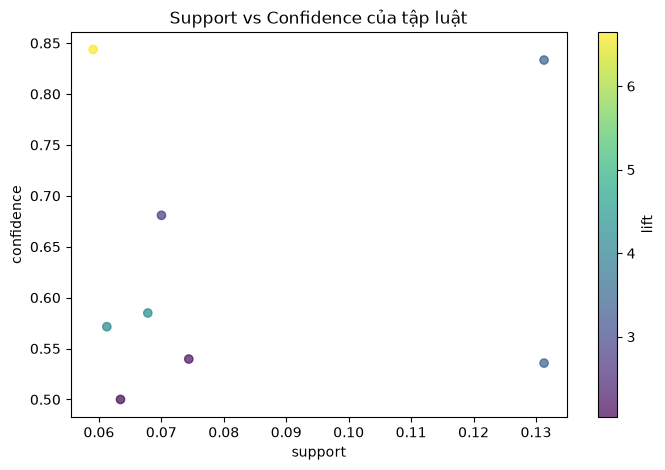

In [12]:
print("Họ tên: Phạm Quốc Thuận - MSSV: 6451071076 - Lớp: CNTT.64")
support = rules['support'].values
confidence = rules['confidence'].values
plt.figure(figsize=(8, 5))
plt.scatter(support, confidence, alpha=0.7, c=rules['lift'], cmap='viridis')
plt.colorbar(label='lift')
plt.xlabel('support'); plt.ylabel('confidence'); plt.title('Support vs Confidence của tập luật')
plt.show()

## Câu 12: FP-Growth với min_sup = 5%, min_conf = 50% và so sánh với Apriori

In [13]:
print("Họ tên: Phạm Quốc Thuận - MSSV: 6451071076 - Lớp: CNTT.64")
start = time.time()
fp_itemsets = fpgrowth(basket_sets, min_support=MIN_SUP, use_colnames=True)
fp_time = time.time() - start
fp_rules = association_rules(fp_itemsets, metric='confidence', min_threshold=MIN_CONF)
print('FP-Growth: %d tập phổ biến, %d luật, thời gian %.3f s' % (len(fp_itemsets), len(fp_rules), fp_time))
print('Apriori  : %d tập phổ biến, %d luật, thời gian %.3f s' % (len(frequent_itemsets), len(rules), apriori_time))
same = set(fp_itemsets['itemsets']) == set(frequent_itemsets['itemsets'])
print('Hai thuật toán cho cùng tập phổ biến:', same)
fp_rules['antecedents'] = fp_rules['antecedents'].apply(lambda x: ', '.join(sorted(x)))
fp_rules['consequents'] = fp_rules['consequents'].apply(lambda x: ', '.join(sorted(x)))
fp_rules[['antecedents', 'consequents', 'support', 'confidence', 'lift']].sort_values('confidence', ascending=False)

Họ tên: Phạm Quốc Thuận - MSSV: 6451071076 - Lớp: CNTT.64
FP-Growth: 59 tập phổ biến, 8 luật, thời gian 0.010 s
Apriori  : 59 tập phổ biến, 8 luật, thời gian 0.006 s
Hai thuật toán cho cùng tập phổ biến: True


,antecedents,consequents,support,confidence,lift
5,RED RETROSPOT CHARLOTTE BAG,WOODLAND CHARLOTTE BAG,0.059081,0.843750,6.648168
0,ROUND SNACK BOXES SET OF 4 FRUITS,ROUND SNACK BOXES SET OF4 WOODLAND,0.131291,0.833333,3.400298
4,SPACEBOY LUNCH BOX,ROUND SNACK BOXES SET OF4 WOODLAND,0.070022,0.680851,2.778116
3,PLASTERS IN TIN CIRCUS PARADE,PLASTERS IN TIN WOODLAND ANIMALS,0.067834,0.584906,4.242887
7,PLASTERS IN TIN SPACEBOY,PLASTERS IN TIN WOODLAND ANIMALS,0.061269,0.571429,4.145125
6,PLASTERS IN TIN WOODLAND ANIMALS,ROUND SNACK BOXES SET OF4 WOODLAND,0.074398,0.539683,2.202098
1,ROUND SNACK BOXES SET OF4 WOODLAND,ROUND SNACK BOXES SET OF 4 FRUITS,0.131291,0.535714,3.400298
2,WOODLAND CHARLOTTE BAG,ROUND SNACK BOXES SET OF4 WOODLAND,0.063457,0.500000,2.040179


**Nhận xét & So sánh:**
- Trên tập dữ liệu khách hàng tại **Đức (`Germany`)** (457 hóa đơn, 1.694 mặt hàng sau khi loại `POSTAGE`), với `min_sup = 5%` và `min_conf = 50%`, cả **Apriori** và **FP-Growth** đều tìm ra chính xác **59 tập phổ biến** và **8 luật kết hợp** trùng khớp 100%.
- Các mặt hàng được mua kèm nhiều nhất tại Đức là dòng hộp đựng đồ ăn nhẹ (`ROUND SNACK BOXES SET OF4 WOODLAND` xuất hiện trong 24,5% hóa đơn, `ROUND SNACK BOXES SET OF 4 FRUITS` 15,8%), túi `CHARLOTTE BAG` và hộp băng cá nhân `PLASTERS IN TIN`.
- Luật mạnh nhất là `RED RETROSPOT CHARLOTTE BAG => WOODLAND CHARLOTTE BAG` (`conf = 84,4%`, `lift = 6,65`) và `ROUND SNACK BOXES SET OF 4 FRUITS => ROUND SNACK BOXES SET OF4 WOODLAND` (`conf = 83,3%`, `sup = 13,1%`, `lift = 3,40`).
- Thời gian thực thi của cả hai thuật toán đều cực nhanh (dưới 0,02 giây) do số lượng hóa đơn của Đức nhỏ (457 hóa đơn).